# Explorer Price Elasticity

In [1]:
import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [4]:
file_path = "data/vehicle_price_volume_monthly.csv"
monthly_df= pd.read_csv(file_path)
monthly_df["price_date"] = pd.to_datetime(monthly_df["price_date"])
monthly_df["price_date"].head()
monthly_df.head()

,price_date,Explorer_price,Traverse_price,Highlander_price,Pilot_price,Palisade_price,Telluride_price,Segment_price,Explorer_volume,Traverse_volume,Highlander_volume,Pilot_volume,Palisade_volume,Telluride_volume
0,2024-01-01,"45,990.681","40,552.044","46,830.144","46,894.477","48,895.398","48,809.486","46,886.061",13432,5685,7844,7470,5957,6843
1,2024-02-01,"45,921.581","41,132.825","46,729.810","46,732.803","48,145.452","48,118.924","46,849.687",11490,5921,8778,9445,7577,8430
2,2024-03-01,"46,453.006","41,978.396","46,313.574","46,098.808","47,823.203","47,830.274","46,762.413",13546,4959,9898,12443,8958,10062
3,2024-04-01,"45,877.921","42,563.146","46,655.751","46,263.385","47,166.740","47,639.665","46,823.594",13664,1992,8329,11680,8385,8833
4,2024-05-01,"45,901.009","47,973.274","46,394.177","46,219.551","46,536.520","46,683.991","46,955.215",12396,8075,7785,12392,8994,10202


#### Inspect the data structure

##### There are 21 monthly observations, January 2024 through September 2025. Each row is a month.

In [5]:
print("Shape:", monthly_df.shape)
print("\nColumn names:")
print(monthly_df.columns.tolist())

monthly_df.info()

Shape: (21, 14)

Column names:
['price_date', 'Explorer_price', 'Traverse_price', 'Highlander_price', 'Pilot_price', 'Palisade_price', 'Telluride_price', 'Segment_price', 'Explorer_volume', 'Traverse_volume', 'Highlander_volume', 'Pilot_volume', 'Palisade_volume', 'Telluride_volume']
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   price_date         21 non-null     datetime64[us]
 1   Explorer_price     21 non-null     float64       
 2   Traverse_price     21 non-null     float64       
 3   Highlander_price   21 non-null     float64       
 4   Pilot_price        21 non-null     float64       
 5   Palisade_price     21 non-null     float64       
 6   Telluride_price    21 non-null     float64       
 7   Segment_price      21 non-null     float64       
 8   Explorer_volume    21 non-null     int64         
 9   Traverse_volu

In [6]:
# Data Range
print("First month:", monthly_df["price_date"].min())
print("Last month:", monthly_df["price_date"].max())
print("Number of months:", monthly_df["price_date"].nunique())

First month: 2024-01-01 00:00:00
Last month: 2025-09-01 00:00:00
Number of months: 21


#### Verify the date range

In [7]:
expected_months = pd.date_range(
    start=monthly_df["price_date"].min(),
    end=monthly_df["price_date"].max(),
    freq="MS"
)

missing_months = expected_months.difference(monthly_df["price_date"])

print("Missing months:")
print(missing_months)

Missing months:
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


#### Check duplicates, missing values, and invalid values

##### Checks includes: unique dates, complete monthly coverage, missing fields, and positive prices and volumes before taking logs.

In [8]:
required_columns = monthly_df.columns
numeric_columns = [
    column for column in required_columns
    if column != "price_date"
]
print(
    "Duplicate months:",
    monthly_df["price_date"].duplicated().sum()
)

print(
    "\nMissing values:",
    monthly_df[required_columns[1:]].isna().sum()
)

print(
    "\nValues less than or equal to zero:",
    (monthly_df[numeric_columns] <= 0).sum()
)

Duplicate months: 0

Missing values: Explorer_price       0
Traverse_price       0
Highlander_price     0
Pilot_price          0
Palisade_price       0
Telluride_price      0
Segment_price        0
Explorer_volume      0
Traverse_volume      0
Highlander_volume    0
Pilot_volume         0
Palisade_volume      0
Telluride_volume     0
dtype: int64

Values less than or equal to zero: Explorer_price       0
Traverse_price       0
Highlander_price     0
Pilot_price          0
Palisade_price       0
Telluride_price      0
Segment_price        0
Explorer_volume      0
Traverse_volume      0
Highlander_volume    0
Pilot_volume         0
Palisade_volume      0
Telluride_volume     0
dtype: int64


####  Examine descriptive statistics

In [9]:
monthly_df[
    [
        "Explorer_price",
        "Explorer_volume",
        "Segment_price"
    ]
].describe()

,Explorer_price,Explorer_volume,Segment_price
count,21.000,21.000,21.000
mean,"47,667.510","11,787.905","46,997.494"
std,"1,688.436","2,166.750",636.006
min,"45,036.998","8,039.000","45,445.574"
25%,"45,990.681","10,358.000","46,766.107"
50%,"47,764.295","11,752.000","46,886.061"
75%,"49,046.555","13,482.000","47,432.556"
max,"50,254.265","16,183.000","48,073.347"


In [10]:
# competitor summary
competitor_price_columns = [
    "Traverse_price",
    "Highlander_price",
    "Pilot_price",
    "Palisade_price",
    "Telluride_price"
]

competitor_volume_columns = [
    "Traverse_volume",
    "Highlander_volume",
    "Pilot_volume",
    "Palisade_volume",
    "Telluride_volume"
]

monthly_df[
    competitor_price_columns + competitor_volume_columns
].describe()

,Traverse_price,Highlander_price,Pilot_price,Palisade_price,Telluride_price,Traverse_volume,Highlander_volume,Pilot_volume,Palisade_volume,Telluride_volume
count,21.000,21.000,21.000,21.000,21.000,21.000,21.000,21.000,21.000,21.000
mean,"46,786.191","49,577.366","46,360.394","46,635.090","46,527.880","8,580.333","5,209.000","11,020.048","8,537.190","9,100.333"
std,"2,672.167","2,300.778",544.213,"1,555.370",846.806,"2,578.159","2,265.888","1,757.694","2,146.213","1,213.492"
min,"40,552.044","46,313.574","45,587.851","43,412.413","45,568.060","1,992.000","1,871.000","7,470.000","5,957.000","6,783.000"
25%,"47,129.405","46,830.144","45,910.549","46,009.157","46,049.937","7,399.000","3,502.000","9,705.000","7,404.000","8,430.000"
50%,"47,756.125","50,814.952","46,257.670","46,536.520","46,257.028","8,920.000","4,657.000","11,568.000","7,991.000","9,000.000"
75%,"48,379.856","51,551.756","46,732.803","46,953.458","46,554.399","10,446.000","7,709.000","12,392.000","8,994.000","10,133.000"
max,"49,066.732","52,435.197","47,439.741","51,312.931","48,809.486","12,297.000","9,898.000","13,845.000","14,941.000","11,362.000"


#### Recalculate quarterly figures

* Quarterly volume is the sum of the three monthly volumes.  
* Quarterly price should be the volume-weighted average transaction price  
* A plain mean of monthly prices would give low-volume months too much weight.

$$
P_Q = \frac{\sum_m \left(P_m V_m\right)}{\sum_m V_m}
$$

In [11]:
vehicles = [
    "Explorer",
    "Traverse",
    "Highlander",
    "Pilot",
    "Palisade",
    "Telluride"
]

monthly_df["quarter"] = monthly_df["price_date"].dt.to_period("Q")

quarterly_rows = []

for quarter, group in monthly_df.groupby("quarter"):
    
    row = {"quarter": str(quarter)}
    
    for vehicle in vehicles:
        
        volume_column = f"{vehicle}_volume"
        price_column = f"{vehicle}_price"
        
        quarterly_volume = group[volume_column].sum()
        
        weighted_price = np.average(
            group[price_column],
            weights=group[volume_column]
        )
        
        row[f"{vehicle}_volume"] = quarterly_volume
        row[f"{vehicle}_price"] = weighted_price
    
    quarterly_rows.append(row)

quarterly_calculated = pd.DataFrame(quarterly_rows)

quarterly_calculated

,quarter,Explorer_volume,Explorer_price,Traverse_volume,Traverse_price,Highlander_volume,Highlander_price,Pilot_volume,Pilot_price,Palisade_volume,Palisade_price,Telluride_volume,Telluride_price
0,2024Q1,38468,"46,132.843",16565,"41,186.640",26520,"46,604.136",29358,"46,505.230",22492,"48,215.731",25335,"48,190.806"
1,2024Q2,34292,"46,108.795",20513,"47,337.321",23823,"46,568.051",35640,"46,286.025",25277,"46,656.343",27815,"46,946.571"
2,2024Q3,26920,"48,137.763",26002,"47,263.092",14589,"48,075.234",36208,"46,043.424",24738,"46,079.338",27103,"46,036.416"
3,2024Q4,34197,"49,642.475",26647,"47,824.007",11260,"51,349.513",37408,"45,795.085",23436,"46,755.524",29631,"46,295.650"
4,2025Q1,31221,"49,065.861",24439,"48,560.423",9074,"51,799.654",32082,"45,869.180",23873,"46,040.260",27541,"46,249.488"
5,2025Q2,39245,"48,457.965",32870,"48,086.527",13669,"51,445.419",31931,"46,860.456",25506,"45,520.474",28833,"46,201.012"
6,2025Q3,43203,"46,151.652",33151,"48,458.809",10454,"50,975.291",28794,"47,129.040",33959,"46,281.678",24849,"45,723.250"


In [12]:
file_path = "data/vehicle_price_volume_quarterly.csv"
quarterly_df= pd.read_csv(file_path)
quarterly_df.head()

,price_date,Explorer_price,Traverse_price,Highlander_price,Pilot_price,Palisade_price,Telluride_price,Explorer_volume,Traverse_volume,Highlander_volume,Pilot_volume,Palisade_volume,Telluride_volume
0,Q1 2024,"46,132.843","41,186.640","46,604.136","46,505.230","48,215.731","48,190.806",38468,16565,26520,29358,22492,25335
1,Q2 2024,"46,108.795","47,337.321","46,568.051","46,286.025","46,656.343","46,946.571",34292,20513,23823,35640,25277,27815
2,Q3 2024,"48,137.763","47,263.092","48,075.234","46,043.424","46,079.338","46,036.416",26920,26002,14589,36208,24738,27103
3,Q4 2024,"49,642.475","47,824.007","51,349.513","45,795.085","46,755.524","46,295.650",34197,26647,11260,37408,23436,29631
4,Q1 2025,"49,065.861","48,560.423","51,799.654","45,869.180","46,040.260","46,249.488",31221,24439,9074,32082,23873,27541


#### Plot Explorer price and volume

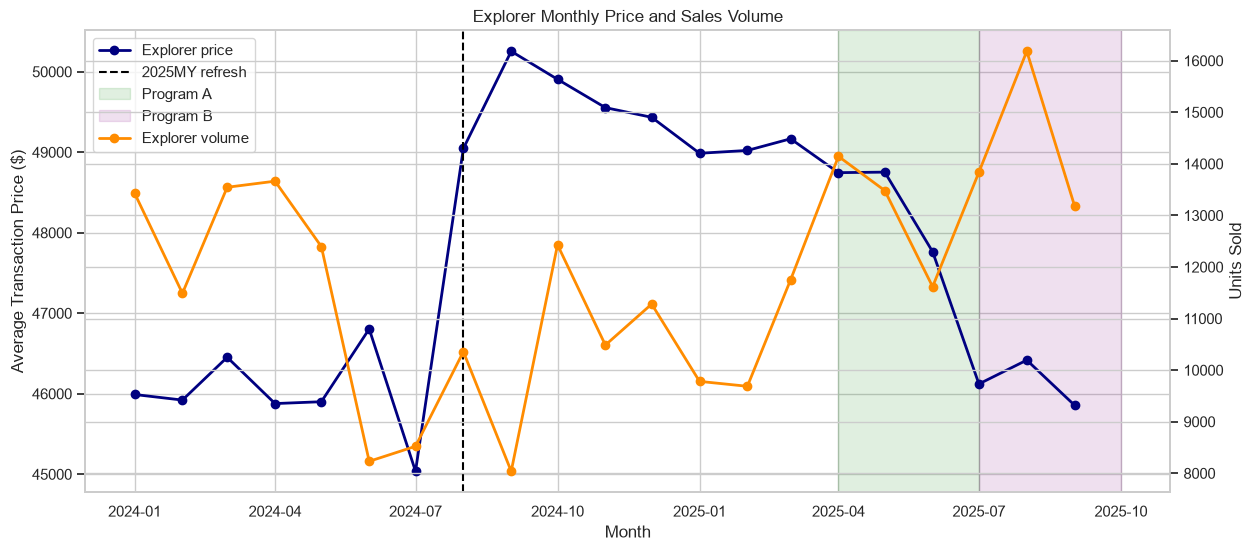

In [13]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax2 = ax1.twinx()

ax1.plot(
    monthly_df["price_date"],
    monthly_df["Explorer_price"],
    color="navy",
    marker="o",
    linewidth=2,
    label="Explorer price"
)

ax2.plot(
    monthly_df["price_date"],
    monthly_df["Explorer_volume"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Explorer volume"
)

ax1.axvline(
    pd.Timestamp("2024-08-01"),
    color="black",
    linestyle="--",
    label="2025MY refresh"
)

ax1.axvspan(
    pd.Timestamp("2025-04-01"),
    pd.Timestamp("2025-07-01"),
    color="green",
    alpha=0.12,
    label="Program A"
)

ax1.axvspan(
    pd.Timestamp("2025-07-01"),
    pd.Timestamp("2025-10-01"),
    color="purple",
    alpha=0.12,
    label="Program B"
)

ax1.set_title("Explorer Monthly Price and Sales Volume")
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Transaction Price ($)")
ax2.set_ylabel("Units Sold")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

plt.show()

* It seems Lower prices is generally associated with higher volume. Prices and volume can move together because of incentives, model refresh, seasonality, inventory, and competitive changes; this chart alone cannot identify a causal price effect.

#### Construct competitor and segment variables

In [14]:
monthly_df["competitor_price_index"] = (
    monthly_df[competitor_price_columns].mean(axis=1)
)

monthly_df["competitor_volume"] = (
    monthly_df[competitor_volume_columns].sum(axis=1)
)

all_volume_columns = [
    f"{vehicle}_volume"
    for vehicle in vehicles
]

monthly_df["segment_volume"] = (
    monthly_df[all_volume_columns].sum(axis=1)
)

monthly_df["Explorer_market_share"] = (
    monthly_df["Explorer_volume"]
    / monthly_df["segment_volume"]
)

monthly_df[
    [
        "price_date",
        "Explorer_price",
        "competitor_price_index",
        "Explorer_volume",
        "competitor_volume",
        "Explorer_market_share"
    ]
].head()

,price_date,Explorer_price,competitor_price_index,Explorer_volume,competitor_volume,Explorer_market_share
0,2024-01-01,"45,990.681","46,396.310",13432,33799,0.284
1,2024-02-01,"45,921.581","46,171.963",11490,40151,0.222
2,2024-03-01,"46,453.006","46,008.851",13546,46320,0.226
3,2024-04-01,"45,877.921","46,057.737",13664,39219,0.258
4,2024-05-01,"45,901.009","46,761.503",12396,47448,0.207


In [42]:
# event and time variables
monthly_df["trend"] = np.arange(len(monthly_df)) # time index (capture gradual increase/decreases in sales over time)

monthly_df["month_number"] = monthly_df["price_date"].dt.month
monthly_df["calendar_quarter"] = monthly_df["price_date"].dt.quarter

# Explorer refresh began in August 2024
monthly_df["refresh"] = (
    monthly_df["price_date"] >= pd.Timestamp("2024-08-01")
).astype(int)

# Program A: Q2 2025
monthly_df["program_a"] = (
    monthly_df["price_date"].between(
        pd.Timestamp("2025-04-01"),
        pd.Timestamp("2025-06-30")
    )
).astype(int)

# Program B: Q3 2025
monthly_df["program_b"] = (
    monthly_df["price_date"].between(
        pd.Timestamp("2025-07-01"),
        pd.Timestamp("2025-09-30")
    )
).astype(int)

monthly_df[
    [
        "price_date",
        "refresh",
        "program_a",
        "program_b"
    ]
]

,price_date,refresh,program_a,program_b
0,2024-01-01,0,0,0
1,2024-02-01,0,0,0
2,2024-03-01,0,0,0
3,2024-04-01,0,0,0
4,2024-05-01,0,0,0
5,2024-06-01,0,0,0
6,2024-07-01,0,0,0
7,2024-08-01,1,0,0
8,2024-09-01,1,0,0
9,2024-10-01,1,0,0


In [16]:
# logarithmic variables
monthly_df["ln_Explorer_volume"] = np.log(
    monthly_df["Explorer_volume"]
)

monthly_df["ln_Explorer_price"] = np.log(
    monthly_df["Explorer_price"]
)

monthly_df["ln_competitor_price"] = np.log(
    monthly_df["competitor_price_index"]
)

monthly_df["ln_competitor_volume"] = np.log(
    monthly_df["competitor_volume"]
)

In [17]:
monthly_df.head()

,price_date,Explorer_price,Traverse_price,Highlander_price,Pilot_price,Palisade_price,Telluride_price,Segment_price,Explorer_volume,Traverse_volume,Highlander_volume,Pilot_volume,Palisade_volume,Telluride_volume,quarter,competitor_price_index,competitor_volume,segment_volume,Explorer_market_share,trend,month_number,calendar_quarter,refresh,program_a,program_b,ln_Explorer_volume,ln_Explorer_price,ln_competitor_price,ln_competitor_volume
0,2024-01-01,"45,990.681","40,552.044","46,830.144","46,894.477","48,895.398","48,809.486","46,886.061",13432,5685,7844,7470,5957,6843,2024Q1,"46,396.310",33799,47231,0.284,0,1,1,0,0,0,9.505,10.736,10.745,10.428
1,2024-02-01,"45,921.581","41,132.825","46,729.810","46,732.803","48,145.452","48,118.924","46,849.687",11490,5921,8778,9445,7577,8430,2024Q1,"46,171.963",40151,51641,0.222,1,2,1,0,0,0,9.349,10.735,10.740,10.600
2,2024-03-01,"46,453.006","41,978.396","46,313.574","46,098.808","47,823.203","47,830.274","46,762.413",13546,4959,9898,12443,8958,10062,2024Q1,"46,008.851",46320,59866,0.226,2,3,1,0,0,0,9.514,10.746,10.737,10.743
3,2024-04-01,"45,877.921","42,563.146","46,655.751","46,263.385","47,166.740","47,639.665","46,823.594",13664,1992,8329,11680,8385,8833,2024Q2,"46,057.737",39219,52883,0.258,3,4,2,0,0,0,9.523,10.734,10.738,10.577
4,2024-05-01,"45,901.009","47,973.274","46,394.177","46,219.551","46,536.520","46,683.991","46,955.215",12396,8075,7785,12392,8994,10202,2024Q2,"46,761.503",47448,59844,0.207,4,5,2,0,0,0,9.425,10.734,10.753,10.767


#### Raw price-volume relationship

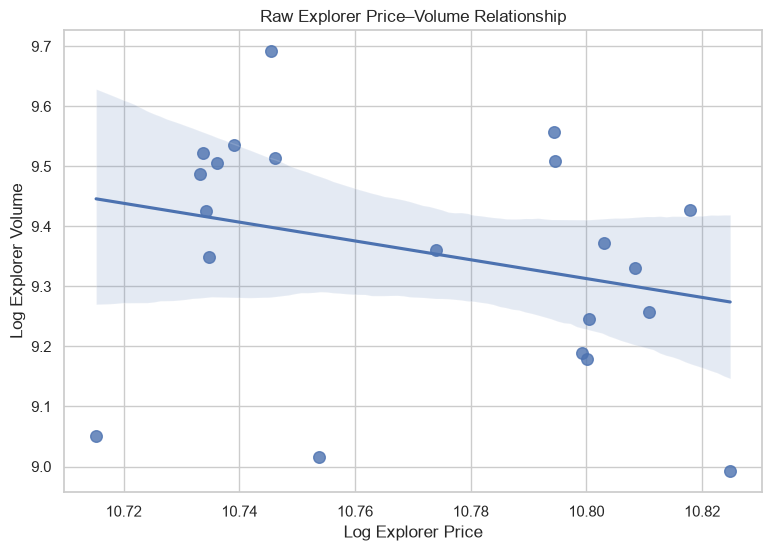

In [18]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=monthly_df,
    x="ln_Explorer_price",
    y="ln_Explorer_volume",
    ci=95,
    scatter_kws={"s": 70}
)

plt.title("Raw Explorer Price–Volume Relationship")
plt.xlabel("Log Explorer Price")
plt.ylabel("Log Explorer Volume")
plt.show()

* **Negative price–volume relationship:** The downward-sloping regression line indicates that higher Explorer prices are generally associated with lower sales volume. This is directionally consistent with economic theory.
* **Demand appears price-sensitive:** Because both axes are expressed in logarithms, the slope of the fitted line represents the raw price elasticity of demand. The estimated slope is negative, meaning a 1% increase in Explorer price is associated with a percentage decrease in Explorer volume.
* **Considerable variation remains unexplained:** The observations are widely scattered around the fitted line. Therefore, price alone does not explain most monthly changes in Explorer sales. Other factors may include seasonality, incentives, inventory, competitor pricing, product changes, interest rates, and overall segment demand.
* **High uncertainty:** The shaded confidence interval is relatively wide, particularly near the lowest and highest price values. This suggests that the elasticity estimate may be statistically uncertain, likely because the dataset contains relatively few monthly observations.
* **Potential influential observations:** A few months have unusually low sales volumes—around log volume 9.0. These observations may strongly influence the regression slope and should be investigated rather than automatically removed.
* **Possible price clusters:** Prices appear concentrated around approximately 10.73–10.75 and 10.79–10.82. This may reflect different pricing periods, model years, incentive strategies, or sales programs.

#### Estimate naive elasticity

In [19]:
naive_model = smf.ols(
    formula="ln_Explorer_volume ~ ln_Explorer_price",
    data=monthly_df
).fit(cov_type="HC1")

print(naive_model.summary())

                            OLS Regression Results                            
Dep. Variable:     ln_Explorer_volume   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     1.381
Date:                Wed, 23 Sep 2026   Prob (F-statistic):              0.255
Time:                        01:41:34   Log-Likelihood:                 6.3313
No. Observations:                  21   AIC:                            -8.663
Df Residuals:                      19   BIC:                            -6.574
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            26.2450     14.38

The model estimated is: ***ln(Explorer Volume)=26.245−1.568ln(Explorer Price)***

The initial **log-log model** suggests that Explorer demand may be price elastic, with a raw **elasticity estimate of −1.57**. However, the effect is **not statistically significant**, the confidence interval is wide, and **price explains only 8.4%** of monthly volume variation. Therefore, this estimate should be **treated as exploratory** and refined using a multivariable time-series model before being used for 2026 pricing decisions.

In [20]:
naive_elasticity = naive_model.params["ln_Explorer_price"]

print(
    f"Naive Explorer price elasticity: "
    f"{naive_elasticity:.2f}"
)

Naive Explorer price elasticity: -1.57


In [21]:
monthly_df.head()

,price_date,Explorer_price,Traverse_price,Highlander_price,Pilot_price,Palisade_price,Telluride_price,Segment_price,Explorer_volume,Traverse_volume,Highlander_volume,Pilot_volume,Palisade_volume,Telluride_volume,quarter,competitor_price_index,competitor_volume,segment_volume,Explorer_market_share,trend,month_number,calendar_quarter,refresh,program_a,program_b,ln_Explorer_volume,ln_Explorer_price,ln_competitor_price,ln_competitor_volume
0,2024-01-01,"45,990.681","40,552.044","46,830.144","46,894.477","48,895.398","48,809.486","46,886.061",13432,5685,7844,7470,5957,6843,2024Q1,"46,396.310",33799,47231,0.284,0,1,1,0,0,0,9.505,10.736,10.745,10.428
1,2024-02-01,"45,921.581","41,132.825","46,729.810","46,732.803","48,145.452","48,118.924","46,849.687",11490,5921,8778,9445,7577,8430,2024Q1,"46,171.963",40151,51641,0.222,1,2,1,0,0,0,9.349,10.735,10.740,10.600
2,2024-03-01,"46,453.006","41,978.396","46,313.574","46,098.808","47,823.203","47,830.274","46,762.413",13546,4959,9898,12443,8958,10062,2024Q1,"46,008.851",46320,59866,0.226,2,3,1,0,0,0,9.514,10.746,10.737,10.743
3,2024-04-01,"45,877.921","42,563.146","46,655.751","46,263.385","47,166.740","47,639.665","46,823.594",13664,1992,8329,11680,8385,8833,2024Q2,"46,057.737",39219,52883,0.258,3,4,2,0,0,0,9.523,10.734,10.738,10.577
4,2024-05-01,"45,901.009","47,973.274","46,394.177","46,219.551","46,536.520","46,683.991","46,955.215",12396,8075,7785,12392,8994,10202,2024Q2,"46,761.503",47448,59844,0.207,4,5,2,0,0,0,9.425,10.734,10.753,10.767


#### Smooth annual seasonality

* Annual seasonality modelled with **sine and cosine** terms. Together, they capture a smooth pattern that repeats every 12 months using 2 coefficients instead of 11 monthly indicators. **With only 21 months of data, the seasonal pattern is uncertain**, so this compact approach preserves degrees of freedom for estimating price and program effects.

$$
\text{sin12}_t=\sin\left(\frac{2\pi t}{12}\right),
\qquad
\text{cos12}_t=\cos\left(\frac{2\pi t}{12}\right)
$$

In [22]:
monthly_df["month_number"] = monthly_df["price_date"].dt.month

monthly_df["sin12"] = np.sin(
    2 * np.pi * monthly_df["month_number"] / 12
)

monthly_df["cos12"] = np.cos(
    2 * np.pi * monthly_df["month_number"] / 12
)

#### Estimate the primary adjusted model

In [23]:
adjusted_formula = """
ln_Explorer_volume
~ ln_Explorer_price
+ ln_competitor_price
+ ln_competitor_volume
+ trend
+ refresh
+ program_a
+ program_b
+ sin12 
+ cos12
"""

adjusted_model = smf.ols(
    formula=adjusted_formula,
    data=monthly_df
).fit(cov_type="HC1")

print(adjusted_model.summary())

                            OLS Regression Results                            
Dep. Variable:     ln_Explorer_volume   R-squared:                       0.753
Model:                            OLS   Adj. R-squared:                  0.552
Method:                 Least Squares   F-statistic:                     6.314
Date:                Wed, 23 Sep 2026   Prob (F-statistic):            0.00293
Time:                        01:41:40   Log-Likelihood:                 20.107
No. Observations:                  21   AIC:                            -20.21
Df Residuals:                      11   BIC:                            -9.769
Df Model:                           9                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                6.4395 

The controls represent:

* *ln_Explorer_price*: Explorer’s own-price elasticity.
* *ln_competitor_price*: effect of competitors becoming more or less expensive.
* *ln_competitor_volume*: overall segment demand conditions.
* *trend*: underlying changes over time.
* *refresh*: demand shift after the August 2024 redesign.
* *program_a*: demand above or below baseline during Program A.
* *program_b*: demand above or below baseline during Program B.
* *sin12* and *cos12*: annual seasonality

#### Extract adjusted elasticity and confidence interval

In [24]:
adjusted_elasticity = adjusted_model.params["ln_Explorer_price"]

elasticity_ci = adjusted_model.conf_int().loc[
    "ln_Explorer_price"
]

elasticity_pvalue = adjusted_model.pvalues[
    "ln_Explorer_price"
]

print(
    f"Adjusted elasticity: {adjusted_elasticity:.2f}"
)

print(
    f"95% confidence interval: "
    f"[{elasticity_ci.iloc[0]:.2f}, "
    f"{elasticity_ci.iloc[1]:.2f}]"
)

print(
    f"P-value: {elasticity_pvalue:.4f}"
)

Adjusted elasticity: -3.46
95% confidence interval: [-10.83, 3.92]
P-value: 0.3584


* Main result: −3.46. Roughly, a 1% higher price aligns with 3.46% lower volume holding controls fixed. The conventional 95% interval spans about −10.83 to +3.92 (p≈0.36), **so the data do not establish a precise price response** or even its sign at that confidence level.
* We have 21 monthly observations and estimate 10 model parameters, leaving 11 residual degrees of freedom. That is a small amount of data for assessing unexplained variation, so I treat **the elasticity estimate as uncertain**.

#### Run a sensitivity model excluding program months

In [25]:
non_program_df = monthly_df[
    (monthly_df["program_a"] == 0)
    & (monthly_df["program_b"] == 0)
].copy()

sensitivity_formula = """
ln_Explorer_volume
~ ln_Explorer_price
+ ln_competitor_price
+ ln_competitor_volume
+ trend
+ refresh
+ sin12 
+ cos12
"""

sensitivity_model = smf.ols(
    formula=sensitivity_formula,
    data=non_program_df
).fit(cov_type="HC1")

print(sensitivity_model.summary())

                            OLS Regression Results                            
Dep. Variable:     ln_Explorer_volume   R-squared:                       0.645
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     13.16
Date:                Wed, 23 Sep 2026   Prob (F-statistic):            0.00151
Time:                        01:41:43   Log-Likelihood:                 12.846
No. Observations:                  15   AIC:                            -9.692
Df Residuals:                       7   BIC:                            -4.028
Df Model:                           7                                         
Covariance Type:                  HC1                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -24.3089 

In [26]:
sensitivity_elasticity = sensitivity_model.params[
    "ln_Explorer_price"
]

print(
    f"No-program elasticity: "
    f"{sensitivity_elasticity:.2f}"
)

No-program elasticity: -3.75


* Excluding the program months changes the elasticity estimate from −3.46 to −3.75, a modest difference. That supports the **directional finding of price sensitivity**, but the small sample and wide uncertainty mean I would use these as **scenarios rather than a precise** 2026 planning coefficient.
* Dropping six promotion months produces −3.75, similar in direction and magnitude. This is a useful sensitivity check, but the remaining 15 observations make the interval wider; **agreement between point estimates is not proof of robustness**.

**1) Estimated Explorer price elasticity that should be used to make go to market decisions in 2026**  
The adjusted model produces an Explorer price-elasticity point estimate of **−3.46**, suggesting that a 1% increase in average transaction price may be associated with approximately a 3.46% reduction in sales volume. However, the estimate is not statistically significant at conventional levels (\(p=0.358\)), and its 95% confidence interval is very wide (\(-10.83\) to \(3.92\)). Therefore, **I would not use −3.46 as a precise standalone elasticity for 2026 go-to-market decisions**. I would treat Explorer as potentially price-sensitive, apply −3.46 only as a downside or high-response scenario, and use a more conservative planning range until additional historical, regional, incentive, inventory, trim-level, and financing data are available.

**Recommendation:** Avoid relying on a single elasticity estimate. The model indicates potential price sensitivity, but the evidence is inconclusive. Use approximately −2.0 as an interim planning assumption, stress-test decisions at −1.0 and −3.46, and validate the estimate with additional data before making large price changes.

#### Compare the elasticity models

In [27]:
def extract_elasticity(model, model_name):
    
    confidence_interval = model.conf_int().loc[
        "ln_Explorer_price"
    ]
    
    return {
        "model": model_name,
        "elasticity": model.params["ln_Explorer_price"],
        "ci_95_low": confidence_interval.iloc[0],
        "ci_95_high": confidence_interval.iloc[1],
        "p_value": model.pvalues["ln_Explorer_price"],
        "observations": int(model.nobs),
        "adjusted_r_squared": model.rsquared_adj
    }


elasticity_comparison = pd.DataFrame([
    extract_elasticity(
        naive_model,
        "Naive"
    ),
    extract_elasticity(
        adjusted_model,
        "Adjusted"
    ),
    extract_elasticity(
        sensitivity_model,
        "Excluding programs"
    )
])

elasticity_comparison.round(3)

,model,elasticity,ci_95_low,ci_95_high,p_value,observations,adjusted_r_squared
0,Naive,-1.568,-4.183,1.047,0.240,21,0.036
1,Adjusted,-3.457,-10.834,3.920,0.358,21,0.552
2,Excluding programs,-3.755,-11.444,3.935,0.339,15,0.291


#### Estimate Program A and Program B conditional lift

For a dummy variable in a log-volume model:

$$
\text{Lift} = 100\left(e^{\beta} - 1\right)
$$

In [28]:
program_results = []

for program_name, variable in [
    ("Program A", "program_a"),
    ("Program B", "program_b")
]:
    
    coefficient = adjusted_model.params[variable]
    confidence_interval = adjusted_model.conf_int().loc[variable]
    
    estimated_lift = 100 * (np.exp(coefficient) - 1)
    lower_lift = 100 * (np.exp(confidence_interval.iloc[0]) - 1)
    upper_lift = 100 * (np.exp(confidence_interval.iloc[1]) - 1)
    
    program_results.append({
        "program": program_name,
        "estimated_volume_lift_pct": estimated_lift,
        "ci_95_low_pct": lower_lift,
        "ci_95_high_pct": upper_lift,
        "p_value": adjusted_model.pvalues[variable]
    })

program_comparison = pd.DataFrame(program_results)

program_comparison.round(2)

,program,estimated_volume_lift_pct,ci_95_low_pct,ci_95_high_pct,p_value
0,Program A,47.560,22.450,77.810,0.000
1,Program B,80.210,25.940,157.850,0.000


In [29]:
comparison_test = adjusted_model.t_test(
    "program_a = program_b"
)

print(comparison_test)

                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.1999      0.177     -1.127      0.260      -0.547       0.148


In [30]:
difference_log = (
    adjusted_model.params["program_b"]
    - adjusted_model.params["program_a"]
)

relative_b_vs_a = 100 * (np.exp(difference_log) - 1)

comparison_pvalue = float(
    np.asarray(comparison_test.pvalue).squeeze()
)

print(
    f"Program B produced an estimated "
    f"{relative_b_vs_a:.1f}% more volume than Program A."
)

print(
    f"P-value for Program A versus Program B: "
    f"{comparison_pvalue:.4f}"
)

Program B produced an estimated 22.1% more volume than Program A.
P-value for Program A versus Program B: 0.2595


After controlling for Explorer price, competitive conditions, market demand, trend, and the product refresh, both programs generated statistically significant volume lift relative to the no-program baseline. Program A was **associated with a 47.6% lift**, while **Program B was associated with an 80.2% lift**. This implies **approximately 22.1% greater** modeled volume under Program B relative to Program A. However, the direct comparison is not statistically significant (\(p=0.2595\)). Therefore, Program B is directionally stronger, but the available data does not establish that it reliably outperformed Program A.

Treat both programs as **effective volume drivers**. Program B is the leading candidate based on its larger point estimate, but the difference is inconclusive. The 2026 choice should therefore be based on total economics—including incentive cost, contribution margin, financing subsidy, lease residual risk, and the possibility of pulling future purchases forward.

#### Compare observed and fitted volume

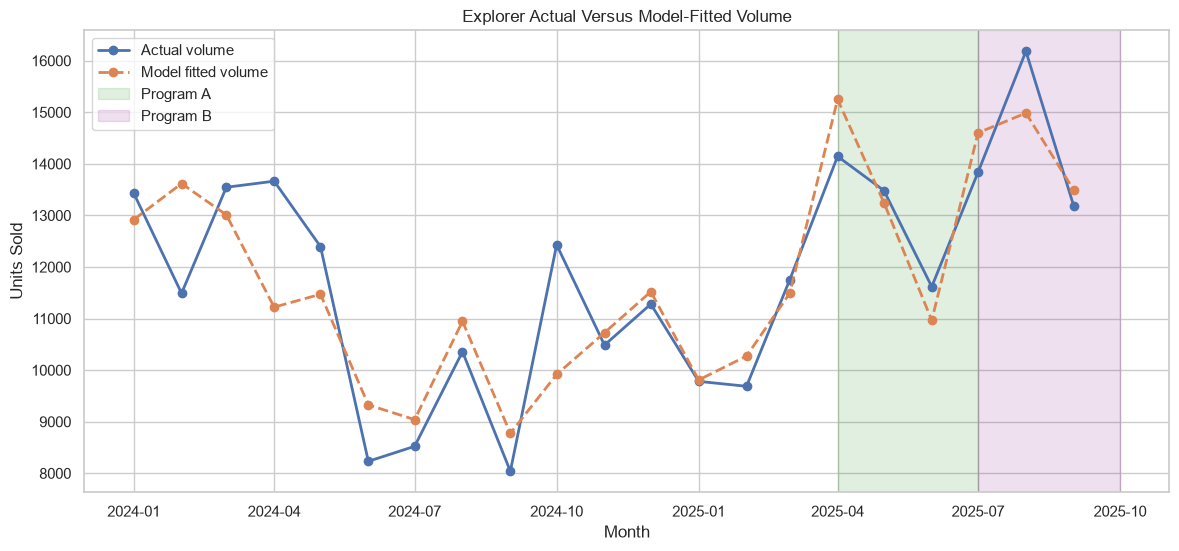

In [31]:
monthly_df["predicted_log_volume"] = adjusted_model.predict(
    monthly_df
)

monthly_df["predicted_volume"] = np.exp(
    monthly_df["predicted_log_volume"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_df["price_date"],
    monthly_df["Explorer_volume"],
    marker="o",
    linewidth=2,
    label="Actual volume"
)

plt.plot(
    monthly_df["price_date"],
    monthly_df["predicted_volume"],
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Model fitted volume"
)

plt.axvspan(
    pd.Timestamp("2025-04-01"),
    pd.Timestamp("2025-07-01"),
    color="green",
    alpha=0.12,
    label="Program A"
)

plt.axvspan(
    pd.Timestamp("2025-07-01"),
    pd.Timestamp("2025-10-01"),
    color="purple",
    alpha=0.12,
    label="Program B"
)

plt.title("Explorer Actual Versus Model-Fitted Volume")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.legend()
plt.show()

Use this chart to show whether the model tracks broad changes. Good in-sample fit does not validate the 2026 forecast, especially with only 21 monthly rows

#### Check model residuals

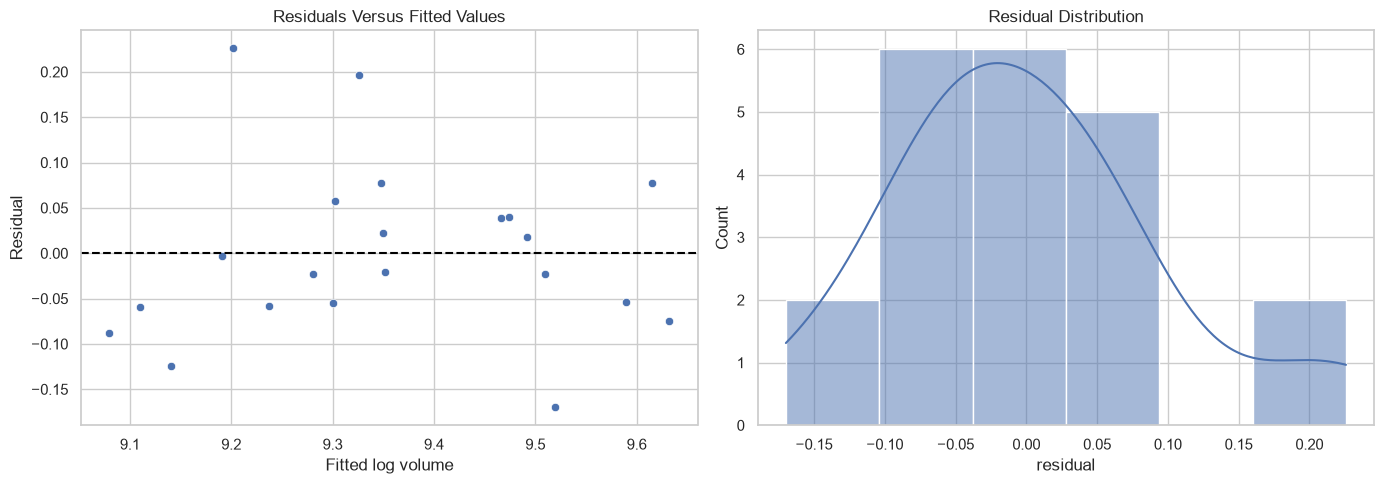

In [32]:
monthly_df["residual"] = adjusted_model.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=monthly_df,
    x="predicted_log_volume",
    y="residual",
    ax=axes[0]
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[0].set_title("Residuals Versus Fitted Values")
axes[0].set_xlabel("Fitted log volume")
axes[0].set_ylabel("Residual")

sns.histplot(
    monthly_df["residual"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

The residuals do not show a clear systematic pattern against fitted sales, which is reassuring. A few months have relatively large errors, however. With only 21 observations, I would inspect those months and test whether they materially change the elasticity estimate. These plots alone do not establish that the model assumptions hold.

#### Test residual autocorrelation

In [33]:
from statsmodels.stats.stattools import durbin_watson

dw_statistic = durbin_watson(adjusted_model.resid)

print(
    f"Durbin-Watson statistic: "
    f"{dw_statistic:.2f}"
)

Durbin-Watson statistic: 2.22


In [34]:
adjusted_model_hac = smf.ols(
    formula=adjusted_formula,
    data=monthly_df
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 2}
)

print(adjusted_model_hac.summary())

                            OLS Regression Results                            
Dep. Variable:     ln_Explorer_volume   R-squared:                       0.753
Model:                            OLS   Adj. R-squared:                  0.552
Method:                 Least Squares   F-statistic:                     25.37
Date:                Wed, 23 Sep 2026   Prob (F-statistic):           4.15e-06
Time:                        01:41:54   Log-Likelihood:                 20.107
No. Observations:                  21   AIC:                            -20.21
Df Residuals:                      11   BIC:                            -9.769
Df Model:                           9                                         
Covariance Type:                  HAC                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                6.4395 

#### Calculate a 2026 planning scenario

In [35]:
planning_elasticity = adjusted_model.params[
    "ln_Explorer_price"
]

planned_price_change_pct = 3

expected_volume_change_pct = (
    planning_elasticity
    * planned_price_change_pct
)

print(
    f"A {planned_price_change_pct:.1f}% price increase "
    f"is associated with an estimated "
    f"{expected_volume_change_pct:.1f}% volume change."
)

A 3.0% price increase is associated with an estimated -10.4% volume change.


#### Compare price, volume, revenue, and market share

In [36]:
import pandas as pd
import numpy as np

monthly_df["program_period"] = np.select(
    [
        monthly_df["program_a"] == 1,
        monthly_df["program_b"] == 1
    ],
    [
        "Program A",
        "Program B"
    ],
    default="No program"
)

# Transaction revenue proxy
monthly_df["Explorer_revenue_proxy"] = (
    monthly_df["Explorer_price"]
    * monthly_df["Explorer_volume"]
)

program_kpis = (
    monthly_df
    .groupby("program_period")
    .agg(
        months=("price_date", "count"),
        average_price=("Explorer_price", "mean"),
        total_volume=("Explorer_volume", "sum"),
        average_monthly_volume=("Explorer_volume", "mean"),
        average_market_share=("Explorer_market_share", "mean"),
        revenue_proxy=("Explorer_revenue_proxy", "sum")
    )
    .reset_index()
)

program_kpis["average_market_share_pct"] = (
    100 * program_kpis["average_market_share"]
)

program_kpis["average_revenue_per_month"] = (
    program_kpis["revenue_proxy"]
    / program_kpis["months"]
)

program_kpis.round(2)

,program_period,months,average_price,total_volume,average_monthly_volume,average_market_share,revenue_proxy,average_market_share_pct,average_revenue_per_month
0,No program,15,"47,823.870",165098,"11,006.530",0.210,"7,881,178,568.380",20.960,"525,411,904.560"
1,Program A,3,"48,421.270",39245,"13,081.670",0.230,"1,901,732,841.130",22.850,"633,910,947.040"
2,Program B,3,"46,131.950",43203,"14,401.000",0.250,"1,993,889,823.540",24.920,"664,629,941.180"


Distinguish volume from economics. A program can gain units and share but cost more in incentives or lower contribution margin. Compare incremental profit using transaction price, variable cost, subsidies, and any pulled-forward demand

#### Compare each program against its counterfactual baseline

In [37]:
# Start with the same data used to fit adjusted_model
comparison_df = monthly_df.copy()

# Prediction under actual observed conditions
comparison_df["predicted_with_program"] = np.exp(
    adjusted_model.predict(comparison_df)
)

# Create a counterfactual version with both programs turned off
counterfactual_df = comparison_df.copy()

counterfactual_df["program_a"] = 0
counterfactual_df["program_b"] = 0

# Predicted volume without either program
comparison_df["predicted_baseline"] = np.exp(
    adjusted_model.predict(counterfactual_df)
)

# Estimated incremental program effect
comparison_df["incremental_program_volume"] = (
    comparison_df["predicted_with_program"]
    - comparison_df["predicted_baseline"]
)

comparison_df["incremental_program_lift_pct"] = (
    100
    * comparison_df["incremental_program_volume"]
    / comparison_df["predicted_baseline"]
)

comparison_df[
    [
        "price_date",
        "Explorer_volume",
        "program_a",
        "program_b",
        "predicted_baseline",
        "predicted_with_program",
        "incremental_program_volume",
        "incremental_program_lift_pct"
    ]
]

,price_date,Explorer_volume,program_a,program_b,predicted_baseline,predicted_with_program,incremental_program_volume,incremental_program_lift_pct
0,2024-01-01,13432,0,0,"12,918.931","12,918.931",0.000,0.000
1,2024-02-01,11490,0,0,"13,618.074","13,618.074",0.000,0.000
2,2024-03-01,13546,0,0,"13,011.170","13,011.170",0.000,0.000
3,2024-04-01,13664,0,0,"11,221.609","11,221.609",0.000,0.000
4,2024-05-01,12396,0,0,"11,471.240","11,471.240",0.000,0.000
5,2024-06-01,8232,0,0,"9,326.003","9,326.003",0.000,0.000
6,2024-07-01,8523,0,0,"9,040.852","9,040.852",0.000,0.000
7,2024-08-01,10358,0,0,"10,947.432","10,947.432",0.000,0.000
8,2024-09-01,8039,0,0,"8,775.976","8,775.976",0.000,0.000
9,2024-10-01,12430,0,0,"9,917.344","9,917.344",0.000,0.000


#### Explorer elasticity with confidence interval

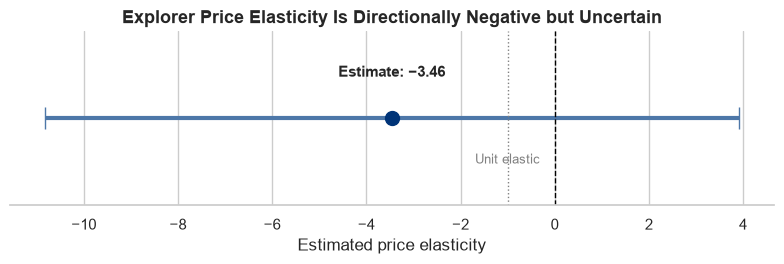

In [38]:
import matplotlib.pyplot as plt

elasticity = -3.46
ci_low = -10.83
ci_high = 3.92

lower_error = elasticity - ci_low
upper_error = ci_high - elasticity

fig, ax = plt.subplots(figsize=(8, 2.8))

ax.errorbar(
    x=elasticity,
    y=0,
    xerr=[[lower_error], [upper_error]],
    fmt="o",
    color="#003478",
    ecolor="#4D77A8",
    elinewidth=3,
    capsize=8,
    markersize=10
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.axvline(
    -1,
    color="gray",
    linestyle=":",
    linewidth=1
)

ax.text(
    elasticity,
    0.12,
    "Estimate: −3.46",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    -1,
    -0.13,
    "Unit elastic",
    ha="center",
    fontsize=9,
    color="gray"
)

ax.set_title(
    "Explorer Price Elasticity Is Directionally Negative but Uncertain",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Estimated price elasticity")
ax.set_yticks([])
ax.set_ylim(-0.25, 0.25)

ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

The point estimate indicates strong price sensitivity, but the confidence interval crosses zero and is very wide. Therefore, I would not use −3.46 as a precise standalone forecast. I would use it as a high-response scenario and make decisions using a planning range.

#### Program lift with confidence intervals

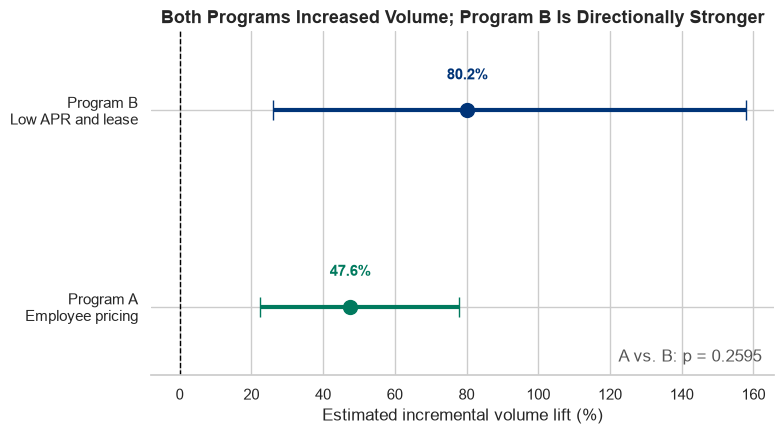

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

program_plot = pd.DataFrame({
    "Program": ["Program A", "Program B"],
    "Lift": [47.56, 80.21],
    "CI_low": [22.45, 25.94],
    "CI_high": [77.81, 157.85]
})

program_plot["lower_error"] = (
    program_plot["Lift"] - program_plot["CI_low"]
)

program_plot["upper_error"] = (
    program_plot["CI_high"] - program_plot["Lift"]
)

colors = ["#007A5E", "#003478"]

fig, ax = plt.subplots(figsize=(8, 4.5))

for i, row in program_plot.iterrows():
    
    ax.errorbar(
        x=row["Lift"],
        y=i,
        xerr=[
            [row["lower_error"]],
            [row["upper_error"]]
        ],
        fmt="o",
        color=colors[i],
        ecolor=colors[i],
        elinewidth=3,
        capsize=7,
        markersize=10
    )
    
    # Percentage label above the error-bar line
    ax.text(
        row["Lift"],
        i + 0.14,
        f'{row["Lift"]:.1f}%',
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=colors[i]
    )

ax.set_ylim(-0.35, 1.40)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "Program A\nEmployee pricing",
    "Program B\nLow APR and lease"
])

ax.set_xlabel("Estimated incremental volume lift (%)")

ax.set_title(
    "Both Programs Increased Volume; Program B Is Directionally Stronger",
    fontsize=13,
    fontweight="bold"
)

ax.text(
    0.98,
    0.04,
    "A vs. B: p = 0.2595",
    transform=ax.transAxes,
    ha="right",
    fontsize=12,
    color="#555555"
)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

Program A produced an estimated 47.6% lift, while Program B produced an estimated 80.2% lift. Program B is directionally stronger, but the confidence intervals overlap, and the direct difference is not statistically significant at \(p=0.2595\). Both programs were effective relative to baseline, but the data does not establish that Program B definitively outperformed Program A.

#### Actual volume versus counterfactual baseline

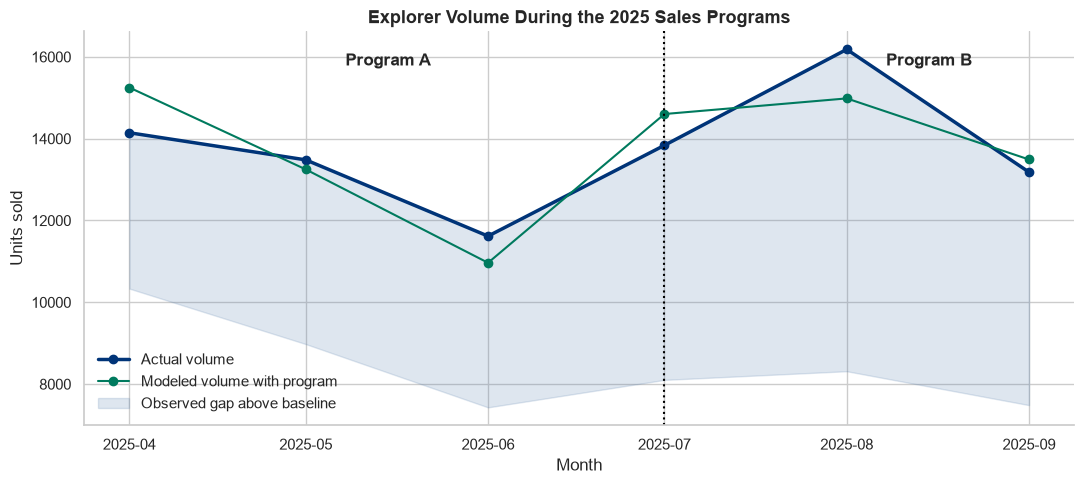

In [40]:
program_months = comparison_df[
    (comparison_df["program_a"] == 1)
    | (comparison_df["program_b"] == 1)
].copy()

program_months["Program"] = program_months["program_a"].map({
    1: "Program A",
    0: "Program B"
})

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    program_months["price_date"],
    program_months["Explorer_volume"],
    marker="o",
    linewidth=2.5,
    color="#003478",
    label="Actual volume"
)

ax.plot(
    program_months["price_date"],
    program_months["predicted_with_program"],
    marker="o",
    color="#007A5E",
    label="Modeled volume with program"
)

ax.fill_between(
    program_months["price_date"],
    program_months["predicted_baseline"],
    program_months["Explorer_volume"],
    color="#4D77A8",
    alpha=0.18,
    label="Observed gap above baseline"
)

ax.axvline(
    pd.Timestamp("2025-07-01"),
    color="black",
    linestyle=":",
    linewidth=1.5
)

ax.text(
    pd.Timestamp("2025-05-15"),
    ax.get_ylim()[1] * 0.95,
    "Program A",
    ha="center",
    fontweight="bold"
)

ax.text(
    pd.Timestamp("2025-08-15"),
    ax.get_ylim()[1] * 0.95,
    "Program B",
    ha="center",
    fontweight="bold"
)

ax.set_title(
    "Explorer Volume During the 2025 Sales Programs",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Units sold")
ax.legend(frameon=False)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

In [41]:
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(adjusted_model.resid)

print(f"Durbin-Watson statistic: {dw:.2f}")

Durbin-Watson statistic: 2.22
